In [44]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report,confusion_matrix

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
import seaborn as sns
from sklearn.metrics import classification_report

## Decision Tree

## importent info 


BMI = weight (kg)/height(m) to the power of 2


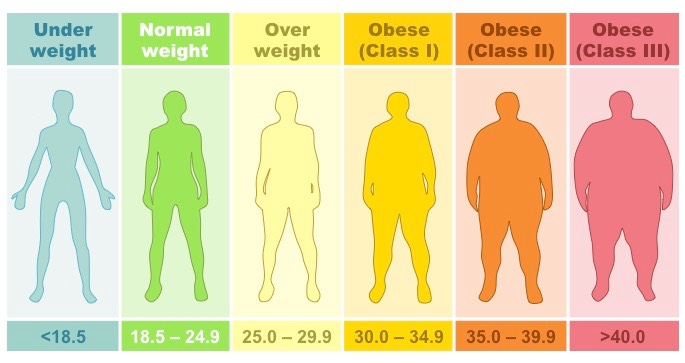


this pic comes from https://wecapable.com/body-mass-index-bmi-importance/


FAVC = Do you eat high caloric food frequently?


FCVC = Do you usually eat vegetables in your meals?


NCP = How many main meals do you have daily?


CAEC = Do you eat any food between meals?


SMOKE = Do you smoke?


CH2O = How much water do you drink daily?


SCC = Do you monitor the calories you eat daily?


FAF = How often do you have physical activity?


TUE = How much time do you use technological devices such as cell phone, videogames, television, computer and others?


CALC = How often do you drink alcohol? 


MTRANS = Which transportation do you usually use?


NObeyesdad = Obesity level

## Import Data

In [45]:



path = "data/ObesityDataSet_raw_and_data_sinthetic.csv"
df = pd.read_csv(path)

## Binary Incodeing 

In [46]:
label_encoders = {}
for col in df.select_dtypes(include=["object"]).columns:
  le = LabelEncoder()
  df[col] = le.fit_transform(df[col])
  label_encoders[col] = le

/var/folders/0h/yb3821ws2z5_3xyp1qxlbynh0000gn/T/ipykernel_23556/1821733809.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=["object"]).columns:


## Separate features and target

In [47]:
X = df.drop(columns=["NObeyesdad"])
y = df["NObeyesdad"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Train

## Graphing The Tree

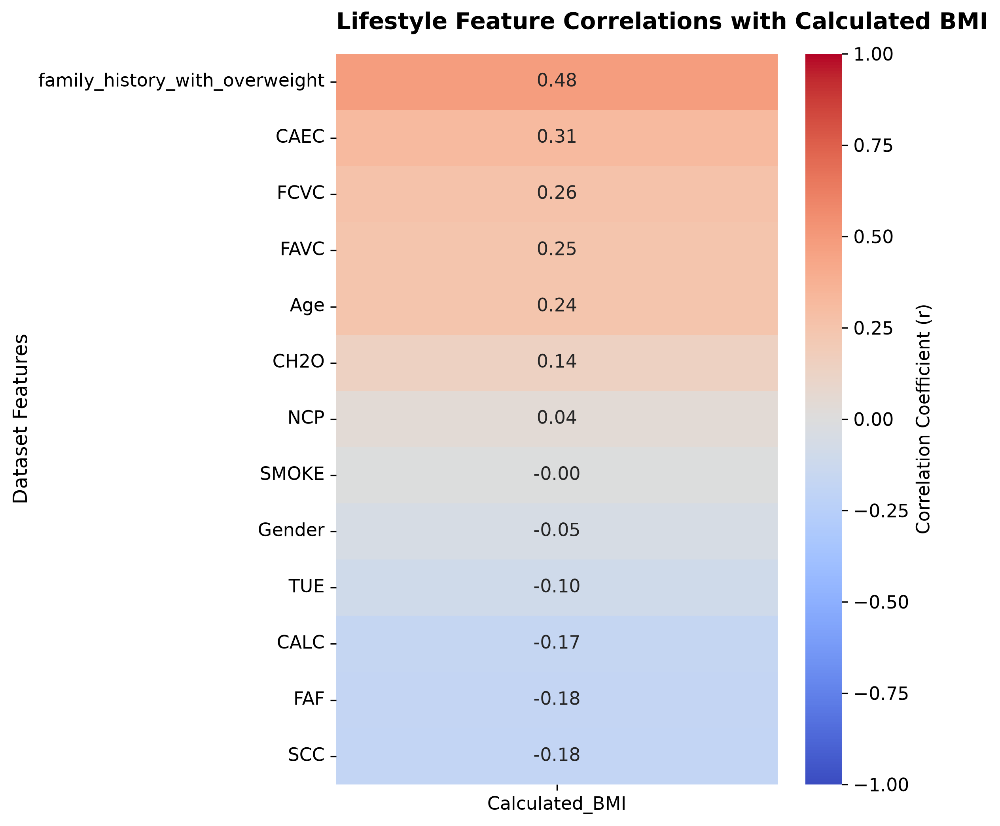

In [48]:
correct_order = [
    "Insufficient_Weight",
    "Normal_Weight",
    "Overweight_Level_I",
    "Overweight_Level_II",
    "Obesity_Type_I",
    "Obesity_Type_II",
    "Obesity_Type_III",
]



# 1. Calculate BMI strictly for analysis
df['Calculated_BMI'] = df['Weight'] / (df['Height'] ** 2)

# 2. Select ONLY numeric columns, but explicitly drop columns that shouldn't be correlated here:
# - 'NObeyesdad' (target variable, which is a circular proxy for BMI)
# - 'MTRANS' (nominal categorical data where numbers have no linear scale)
# - Raw 'Weight' and 'Height' (optional: since BMI is calculated directly from them, 
cols_to_exclude = ['NObeyesdad', 'MTRANS', 'Weight', 'Height', 'Calculated_BMI']

# Get all numeric columns except the ones we want to exclude
numeric_features = df.select_dtypes(include=['number']).drop(columns=cols_to_exclude, errors='ignore')

# Add Calculated_BMI back temporarily so we can compute its correlations
numeric_features['Calculated_BMI'] = df['Calculated_BMI']

# 3. Compute correlation matrix and extract ONLY the BMI column
corr_matrix = numeric_features.corr()
bmi_corr = corr_matrix[['Calculated_BMI']].sort_values(by='Calculated_BMI', ascending=False)

# Drop 'Calculated_BMI' from itself so it doesn't show a redundant 1.0 correlation row
bmi_corr = bmi_corr.drop('Calculated_BMI', errors='ignore')

# 4. Plot as a clean, single-column vertical heatmap
plt.figure(figsize=(6, 8), dpi=300)
sns.heatmap(
    bmi_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, 
    vmax=1,
    cbar_kws={'label': 'Correlation Coefficient (r)'}
)

plt.title("Lifestyle Feature Correlations with Calculated BMI", fontsize=14, pad=15)
plt.ylabel("Dataset Features", fontsize=12)

plt.show()









## Tree


================ All Features (Depth = 3) ================
Test Accuracy: 63.36%

Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight      0.829     0.607     0.701        56
      Normal_Weight      0.500     0.371     0.426        62
 Overweight_Level_I      0.789     0.192     0.309        78
Overweight_Level_II      0.815     0.914     0.862        58
     Obesity_Type_I      1.000     1.000     1.000        63
    Obesity_Type_II      0.493     0.661     0.565        56
   Obesity_Type_III      0.377     0.860     0.524        50

           accuracy                          0.634       423
          macro avg      0.686     0.658     0.627       423
       weighted avg      0.699     0.634     0.616       423

Saved tree plot to: pictures/tree_all_features_depth_3.svg


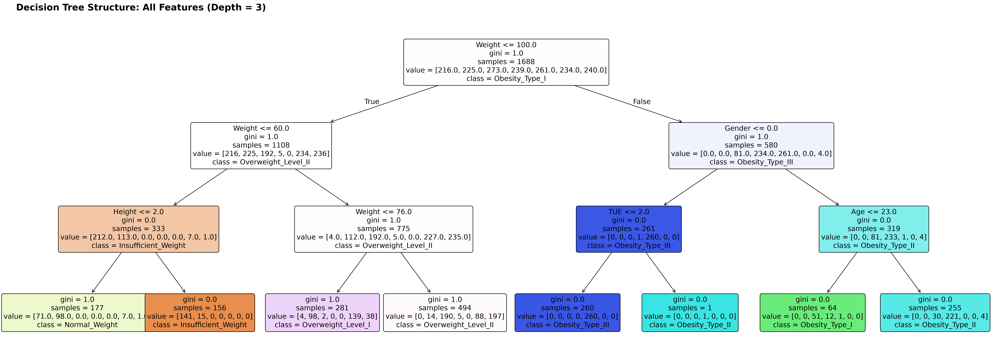

Saved confusion matrix to: pictures/confusion_matrix_all_features_depth_3.png



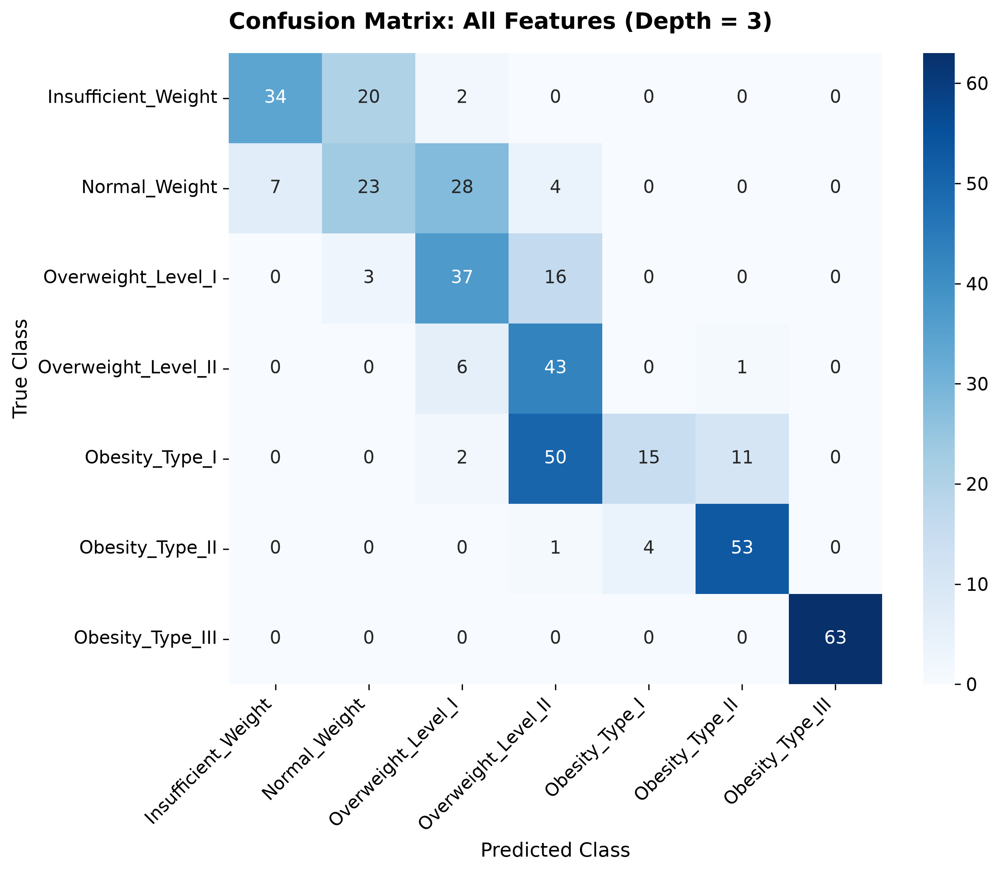


================ Lifestyle Only (Depth = 3) ================
Test Accuracy: 49.17%

Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight      0.404     0.339     0.369        56
      Normal_Weight      0.407     0.355     0.379        62
 Overweight_Level_I      0.343     0.769     0.474        78
Overweight_Level_II      0.590     0.793     0.676        58
     Obesity_Type_I      0.884     0.968     0.924        63
    Obesity_Type_II      0.000     0.000     0.000        56
   Obesity_Type_III      0.000     0.000     0.000        50

           accuracy                          0.492       423
          macro avg      0.375     0.461     0.403       423
       weighted avg      0.389     0.492     0.422       423



/Users/zmaughan/.pyenv/versions/3.13.7/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/zmaughan/.pyenv/versions/3.13.7/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/zmaughan/.pyenv/versions/3.13.7/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier,

Saved tree plot to: pictures/tree_lifestyle_only_depth_3.svg


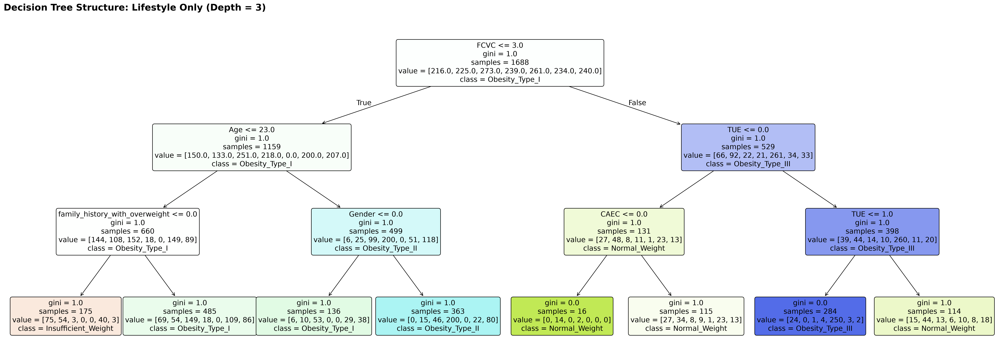

Saved confusion matrix to: pictures/confusion_matrix_lifestyle_only_depth_3.png



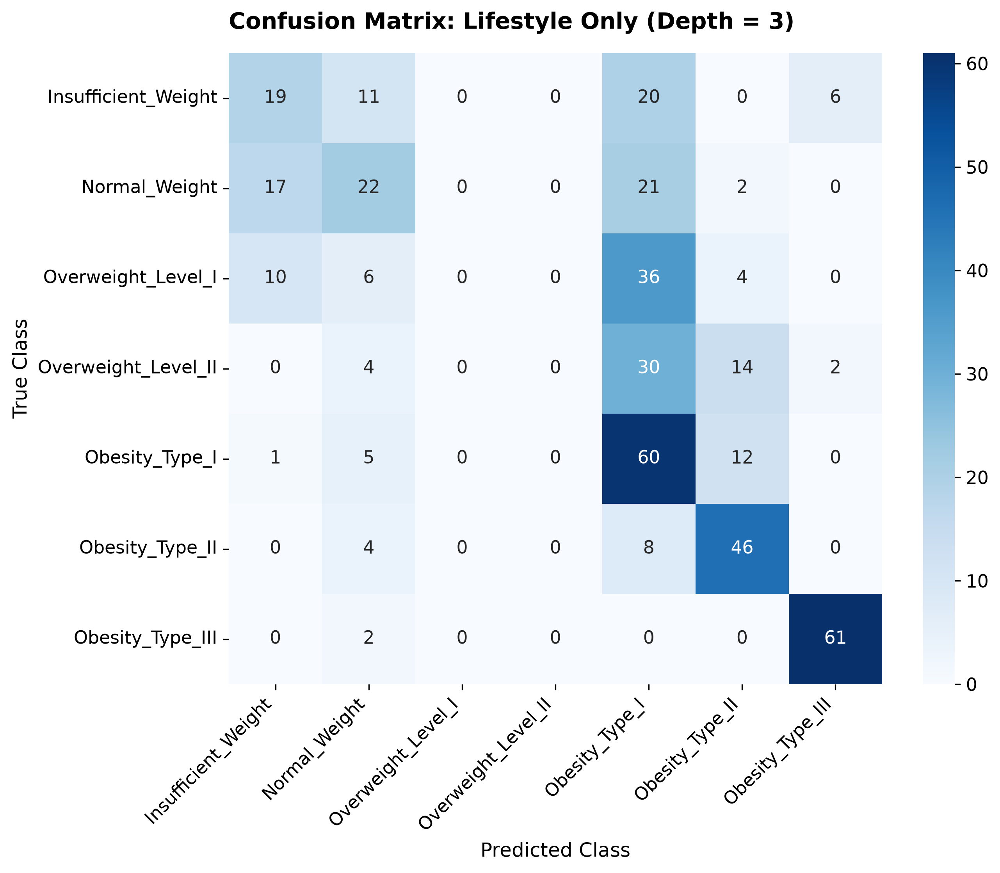


================ All Features (Depth = 6) ================
Test Accuracy: 90.31%

Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight      0.900     0.964     0.931        56
      Normal_Weight      0.820     0.806     0.813        62
 Overweight_Level_I      0.947     0.923     0.935        78
Overweight_Level_II      0.965     0.948     0.957        58
     Obesity_Type_I      1.000     1.000     1.000        63
    Obesity_Type_II      0.754     0.875     0.810        56
   Obesity_Type_III      0.951     0.780     0.857        50

           accuracy                          0.903       423
          macro avg      0.905     0.900     0.900       423
       weighted avg      0.907     0.903     0.903       423

Saved tree plot to: pictures/tree_all_features_depth_6.svg


Saved confusion matrix to: pictures/confusion_matrix_all_features_depth_6.png



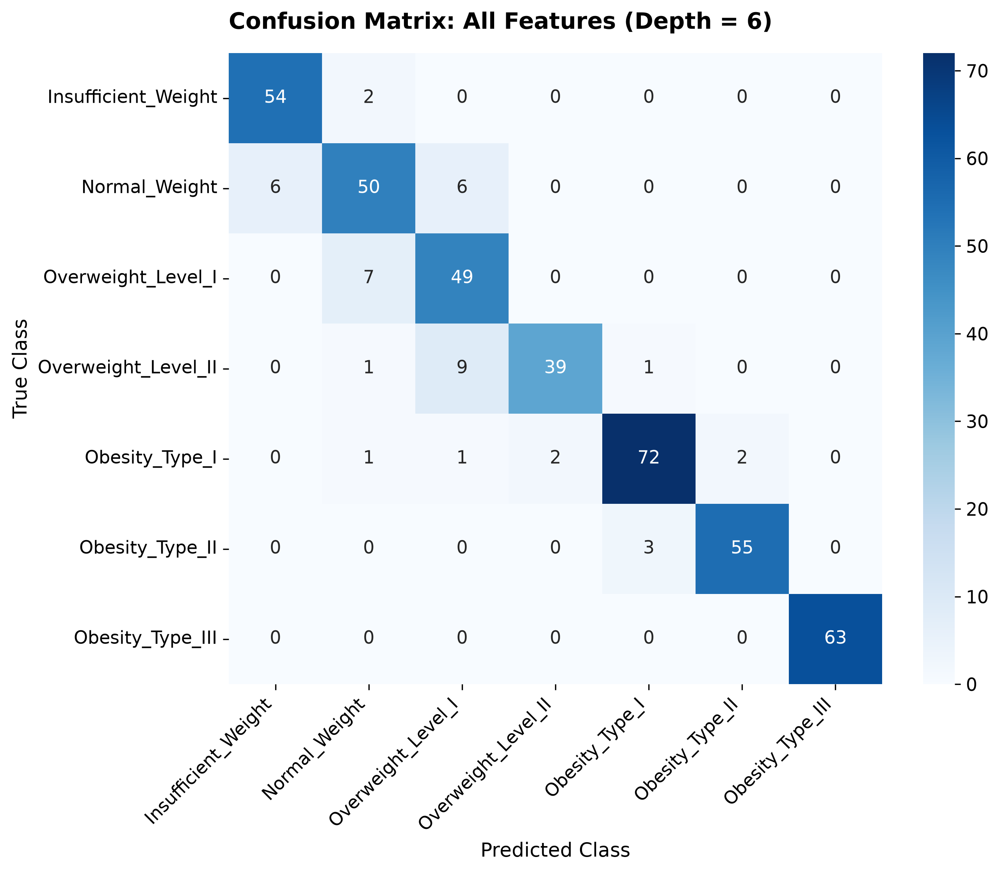


================ Lifestyle Only (Depth = 6) ================
Test Accuracy: 67.85%

Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight      0.846     0.589     0.695        56
      Normal_Weight      0.545     0.677     0.604        62
 Overweight_Level_I      0.566     0.769     0.652        78
Overweight_Level_II      0.710     0.845     0.772        58
     Obesity_Type_I      0.984     1.000     0.992        63
    Obesity_Type_II      0.800     0.357     0.494        56
   Obesity_Type_III      0.465     0.400     0.430        50

           accuracy                          0.678       423
          macro avg      0.702     0.663     0.663       423
       weighted avg      0.701     0.678     0.671       423

Saved tree plot to: pictures/tree_lifestyle_only_depth_6.svg


Saved confusion matrix to: pictures/confusion_matrix_lifestyle_only_depth_6.png



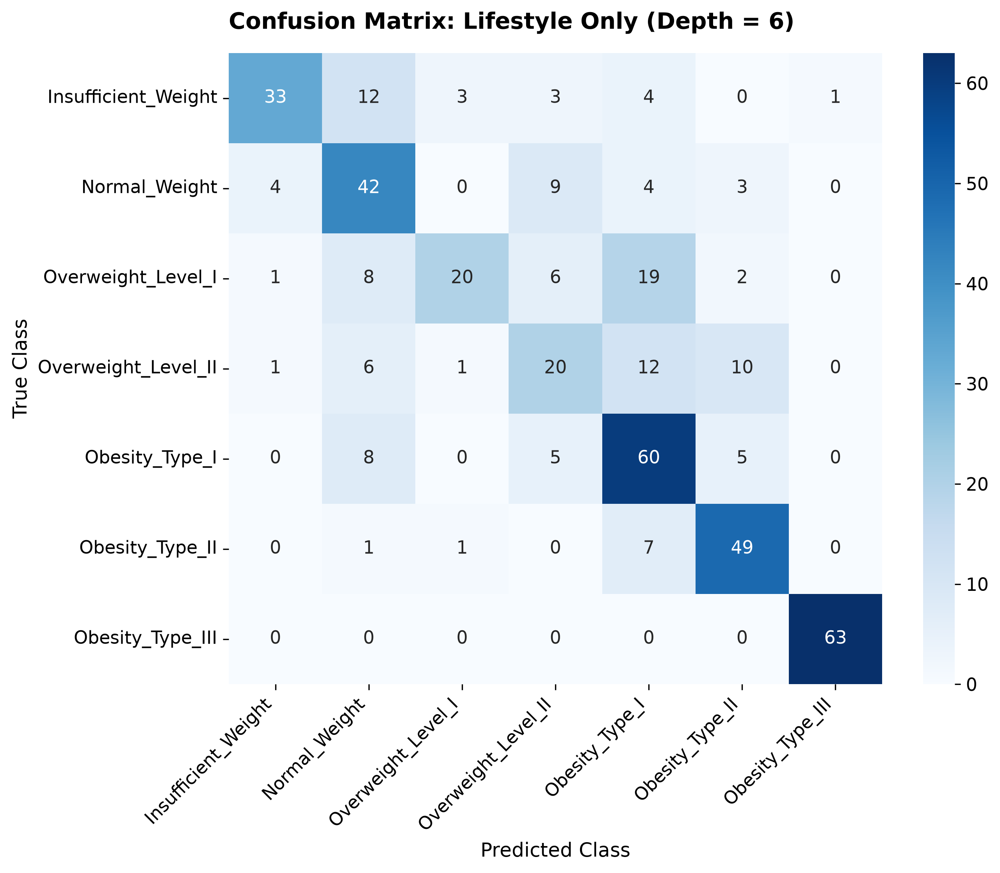

In [49]:









import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Create a dedicated folder for pictures/plots (leaving your data folder untouched)
output_dir = "pictures"
os.makedirs(output_dir, exist_ok=True)

# 2. Define Feature Sets
cols_to_drop_all = ["NObeyesdad", "Calculated_BMI", "SMOKE"]
X_all = df.drop(columns=cols_to_drop_all, errors="ignore")

cols_to_drop_lifestyle = ["NObeyesdad", "Calculated_BMI", "SMOKE", "Height", "Weight"]
X_lifestyle = df.drop(columns=cols_to_drop_lifestyle, errors="ignore")

y = df["NObeyesdad"]

# Split data for both feature sets (using the same random state for fair comparison)
X_all_train, X_all_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, random_state=42
)
X_life_train, X_life_test, _, _ = train_test_split(
    X_lifestyle, y, test_size=0.2, random_state=42
)

# 3. Configure the 4 Tree Experiments (models_config)
models_config = [
    {
        "name": "All Features (Depth = 3)",
        "model": DecisionTreeClassifier(max_depth=3, random_state=42),
        "X_tr": X_all_train,
        "X_te": X_all_test,
        "features": X_all.columns,
        "tree_figsize": (35, 12),
        "fontsize": 14,
    },
    {
        "name": "Lifestyle Only (Depth = 3)",
        "model": DecisionTreeClassifier(max_depth=3, random_state=42),
        "X_tr": X_life_train,
        "X_te": X_life_test,
        "features": X_lifestyle.columns,
        "tree_figsize": (35, 12),
        "fontsize": 14,
    },
    {
        "name": "All Features (Depth = 6)",
        "model": DecisionTreeClassifier(max_depth=6, random_state=42),
        "X_tr": X_all_train,
        "X_te": X_all_test,
        "features": X_all.columns,
        "tree_figsize": (110, 32),  
        "fontsize": 9,                 
    },
    {
        "name": "Lifestyle Only (Depth = 6)",
        "model": DecisionTreeClassifier(max_depth=6, random_state=42),
        "X_tr": X_life_train,
        "X_te": X_life_test,
        "features": X_lifestyle.columns,
        "tree_figsize": (110, 32),  
        "fontsize": 7,               
    },
]

# Map your text labels to encoded integer values using your correct_order
class_indices = list(label_encoders["NObeyesdad"].transform(correct_order))

# 4. Train, Evaluate, and Plot Each Model in the Loop
for cfg in models_config:
    print(f"\n================ {cfg['name']} ================")
    
    # Fit model
    clf = cfg["model"]
    clf.fit(cfg["X_tr"], y_train)
    
    # Predictions
    y_pred = clf.predict(cfg["X_te"])
    
    # Print Metrics
    acc = accuracy_score(y_test, y_pred)
    print(f"Test Accuracy: {acc * 100:.2f}%\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=correct_order, digits=3))
    
    # Create file-safe string tag
    file_tag = cfg["name"].lower().replace(" = ", "_").replace("(", "").replace(")", "").replace(" ", "_")
    
    # Plot and Save Tree Diagram (SVG format inside 'pictures/' folder)
    plt.figure(figsize=cfg["tree_figsize"], dpi=300)
    plot_tree(
        clf,
        feature_names=list(cfg["features"]),
        class_names=list(label_encoders["NObeyesdad"].classes_),
        filled=True,
        rounded=True,
        fontsize=cfg["fontsize"],
        precision=0
    )
    plt.title(f"Decision Tree Structure: {cfg['name']}", fontsize=18, pad=20)
    
    tree_filename = os.path.join(output_dir, f"tree_{file_tag}.svg")
    plt.savefig(tree_filename, format="svg", bbox_inches="tight")
    print(f"Saved tree plot to: {tree_filename}")
    plt.show()
    
    # Plot and Save Ordered Confusion Matrix Heatmap (PNG format inside 'pictures/' folder)
    cm = confusion_matrix(y_test, y_pred, labels=class_indices)
    plt.figure(figsize=(9, 7), dpi=300)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=correct_order,
        yticklabels=correct_order
    )
    plt.xlabel("Predicted Class", fontsize=12)
    plt.ylabel("True Class", fontsize=12)
    plt.title(f"Confusion Matrix: {cfg['name']}", fontsize=14, pad=15)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    
    cm_filename = os.path.join(output_dir, f"confusion_matrix_{file_tag}.png")
    plt.savefig(cm_filename, dpi=300, bbox_inches="tight")
    print(f"Saved confusion matrix to: {cm_filename}\n")
    plt.show()


# Neural Network

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report,confusion_matrix

## Read

In [51]:
obesity = pd.read_csv("data/ObesityDataSet_raw_and_data_sinthetic.csv")

display(obesity.head())
display(obesity.NObeyesdad.value_counts())

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64

## Clean

In [52]:
obesity = obesity.drop_duplicates().reset_index(drop=True)

survey_cols = ['FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
obesity['synthetic'] = (obesity[survey_cols + ['Age']] % 1 != 0).any(axis=1)
display(obesity.groupby('NObeyesdad').synthetic.mean().round(2))

obesity[survey_cols] = obesity[survey_cols].round().astype(int)

NObeyesdad
Insufficient_Weight    0.87
Normal_Weight          0.00
Obesity_Type_I         0.87
Obesity_Type_II        0.96
Obesity_Type_III       0.99
Overweight_Level_I     0.80
Overweight_Level_II    0.80
Name: synthetic, dtype: float64

In [53]:
freq = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}

X = pd.DataFrame({
    'Male': (obesity.Gender == 'Male').astype(int),
    'Age': obesity.Age,
    'FamilyHistory': (obesity.family_history_with_overweight == 'yes').astype(int),
    'HighCalFood': (obesity.FAVC == 'yes').astype(int),
    'Veggies': obesity.FCVC,
    'MainMeals': obesity.NCP,
    'Snacking': obesity.CAEC.map(freq),
    'Smoke': (obesity.SMOKE == 'yes').astype(int),
    'Water': obesity.CH2O,
    'CountsCalories': (obesity.SCC == 'yes').astype(int),
    'Exercise': obesity.FAF,
    'ScreenTime': obesity.TUE,
    'Alcohol': obesity.CALC.map(freq),
})
X = pd.concat([X, pd.get_dummies(obesity.MTRANS).astype(int)], axis=1)
# number the classes from lightest to heaviest
order = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
         'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
y = obesity['NObeyesdad'].map({name: i for i, name in enumerate(order)})

display(X.head())

,Male,Age,FamilyHistory,HighCalFood,Veggies,MainMeals,Snacking,Smoke,Water,CountsCalories,Exercise,ScreenTime,Alcohol,Automobile,Bike,Motorbike,Public_Transportation,Walking
0,0,21.0,1,0,2,3,1,0,2,0,0,1,0,0,0,0,1,0
1,0,21.0,1,0,3,3,1,1,3,1,3,0,1,0,0,0,1,0
2,1,23.0,1,0,2,3,1,0,2,0,2,1,2,0,0,0,1,0
3,1,27.0,0,0,3,3,1,0,2,0,2,0,2,0,0,0,0,1
4,1,22.0,0,0,2,1,1,0,2,0,0,0,1,0,0,0,1,0


## Train test split

In [54]:
X_train, X_test, y_train, y_test, syn_train, syn_test = train_test_split(
    X, y, obesity.synthetic, test_size=0.25, random_state=42, stratify=y)

X.columns
y.unique()

array([1, 2, 3, 4, 0, 5, 6])

## Pre process

Standardize using only the training data and apply the same scaling to the test set

In [55]:
scaler = StandardScaler()

# Fit only to the training data
scaler.fit(X_train)

# Now apply the transformations to the data:
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

X_train

array([[-0.9816382 , -0.34507071,  0.46679635, ..., -0.07605302,
         0.58497482, -0.15344315],
       [ 1.01870526, -0.69756058,  0.46679635, ..., -0.07605302,
         0.58497482, -0.15344315],
       [-0.9816382 , -0.85585386,  0.46679635, ..., -0.07605302,
         0.58497482, -0.15344315],
       ...,
       [-0.9816382 ,  0.23776739,  0.46679635, ..., -0.07605302,
         0.58497482, -0.15344315],
       [ 1.01870526,  0.25219915,  0.46679635, ..., -0.07605302,
         0.58497482, -0.15344315],
       [-0.9816382 ,  3.00275713,  0.46679635, ..., -0.07605302,
        -1.70947529, -0.15344315]], shape=(1565, 18))

## Train the models

In [56]:
mlp_a = MLPClassifier(hidden_layer_sizes=(10,), max_iter=3000, random_state=42)
mlp_b = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=3000, random_state=42)
mlp_c = MLPClassifier(hidden_layer_sizes=(64, 32, 16), max_iter=3000, random_state=42)

mlp_a.fit(X_train,y_train)
mlp_b.fit(X_train,y_train)
mlp_c.fit(X_train,y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(64, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",3000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


## Predictions and Evaluations

In [57]:
for name, mlp in [('A (10)', mlp_a), ('B (32, 16)', mlp_b), ('C (64, 32, 16)', mlp_c)]:
    predictions = mlp.predict(X_test)
    print('Network', name)
    print('Training accuracy: {:.3f}'.format(mlp.score(X_train, y_train)))
    print('Test accuracy:     {:.3f}'.format(mlp.score(X_test, y_test)))
    print(confusion_matrix(y_test,predictions))
    print(classification_report(y_test,predictions,target_names=order))
    print()

Network A (10)
Training accuracy: 0.742
Test accuracy:     0.690
[[53  8  3  1  2  0  0]
 [12 37  6  6  6  3  0]
 [ 4 12 28  4 12  7  2]
 [ 2  7  7 36 10  9  2]
 [ 0  2 14  4 60  7  1]
 [ 1  1  0  4  2 66  0]
 [ 0  1  0  0  0  0 80]]
                     precision    recall  f1-score   support

Insufficient_Weight       0.74      0.79      0.76        67
      Normal_Weight       0.54      0.53      0.54        70
 Overweight_Level_I       0.48      0.41      0.44        69
Overweight_Level_II       0.65      0.49      0.56        73
     Obesity_Type_I       0.65      0.68      0.67        88
    Obesity_Type_II       0.72      0.89      0.80        74
   Obesity_Type_III       0.94      0.99      0.96        81

           accuracy                           0.69       522
          macro avg       0.68      0.68      0.68       522
       weighted avg       0.68      0.69      0.68       522


Network B (32, 16)
Training accuracy: 0.970
Test accuracy:     0.711
[[50 11  5  0  1  0  0

In [58]:
print('This dataset has {} input nodes and {} output node(s)'.format(len(X.columns), len(y.unique())))
for name, mlp in [('A', mlp_a), ('B', mlp_b), ('C', mlp_c)]:
    print()
    print('Network {}: {} 2D arrays of coefficients, one for each layer'.format(name, len(mlp.coefs_)))
    for l in range(len(mlp.coefs_)):
        m = len(mlp.coefs_[l])
        n = len(mlp.coefs_[l][0])
        print('  {}: {}x{} ({} nodes feeding into a layer of {} nodes)'.format(l, m, n, m, n))
    print('Each layer has {} intercepts, one for each node'.format([len(b) for b in mlp.intercepts_]))

This dataset has 18 input nodes and 7 output node(s)

Network A: 2 2D arrays of coefficients, one for each layer
  0: 18x10 (18 nodes feeding into a layer of 10 nodes)
  1: 10x7 (10 nodes feeding into a layer of 7 nodes)
Each layer has [10, 7] intercepts, one for each node

Network B: 3 2D arrays of coefficients, one for each layer
  0: 18x32 (18 nodes feeding into a layer of 32 nodes)
  1: 32x16 (32 nodes feeding into a layer of 16 nodes)
  2: 16x7 (16 nodes feeding into a layer of 7 nodes)
Each layer has [32, 16, 7] intercepts, one for each node

Network C: 4 2D arrays of coefficients, one for each layer
  0: 18x64 (18 nodes feeding into a layer of 64 nodes)
  1: 64x32 (64 nodes feeding into a layer of 32 nodes)
  2: 32x16 (32 nodes feeding into a layer of 16 nodes)
  3: 16x7 (16 nodes feeding into a layer of 7 nodes)
Each layer has [64, 32, 16, 7] intercepts, one for each node


## Draw Neural Networks

In [59]:
# you may need to install networkx with pip
import networkx as nx
import colorsys

def show_ann(mlp):
    hidden_layers_n = len(mlp.coefs_)-1
    layers_n = hidden_layers_n + 2
    input_neurons_n = len(mlp.coefs_[0])
    hidden_neurons_n = [len(mlp.coefs_[i+1]) for i in range(hidden_layers_n)]
    output_neurons_n = len(mlp.coefs_[-1][0])

    G = nx.DiGraph()
    pos = {}

    # Create the neurons of the input layer
    for i in range(input_neurons_n):
        pos['Layer0_{}'.format(i)] = (i,layers_n-1)

    for j in range(hidden_layers_n):
        # Create the neurons of the j'th hidden layer
        prev_layer = j
        cur_layer = j+1
        if (j == 0):
            prev_size = input_neurons_n
        else:
            prev_size = hidden_neurons_n[j-1]
        for i in range(hidden_neurons_n[j]):
            pos['Layer{}_{}'.format(cur_layer,i)] = (i,layers_n-1-cur_layer)
            for k in range(prev_size):
                w = mlp.coefs_[prev_layer][k][i]
                G.add_edge('Layer{}_{}'.format(prev_layer,k),'Layer{}_{}'.format(cur_layer,i), weight=w)

    # Create the neurons of the output layer
    prev_layer = hidden_layers_n
    cur_layer = hidden_layers_n+1
    for i in range(output_neurons_n):
        pos['Layer{}_{}'.format(cur_layer,i)] = (i,layers_n-1-cur_layer)
        for k in range(hidden_neurons_n[-1]):
            w = mlp.coefs_[prev_layer][k][i]
            G.add_edge('Layer{}_{}'.format(prev_layer,k),'Layer{}_{}'.format(cur_layer,i), weight=w)

    edges = G.edges()
    colors = [colorsys.hsv_to_rgb(0 if G[u][v]['weight'] < 0 else 0.65,
                                  1,#min(1, abs(G[u][v]['weight'])),
                                  1) for u,v in edges]
    weights = [abs(G[u][v]['weight'])*2 for u,v in edges]

    nx.draw(G, pos, node_color='y', node_size=450, width=weights, edge_color=colors)

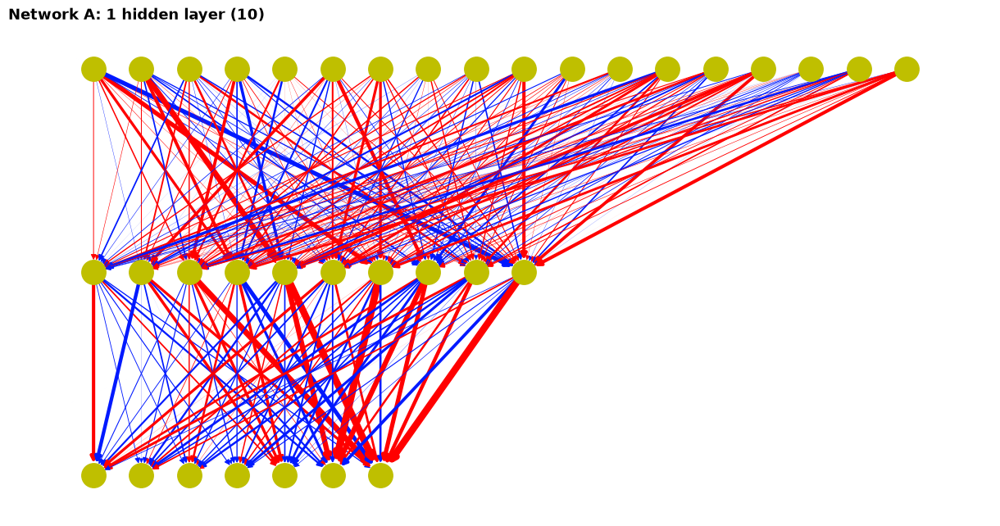

In [60]:
plt.figure(figsize=(12, 6))
show_ann(mlp_a)
plt.title('Network A: 1 hidden layer (10)')
plt.show()

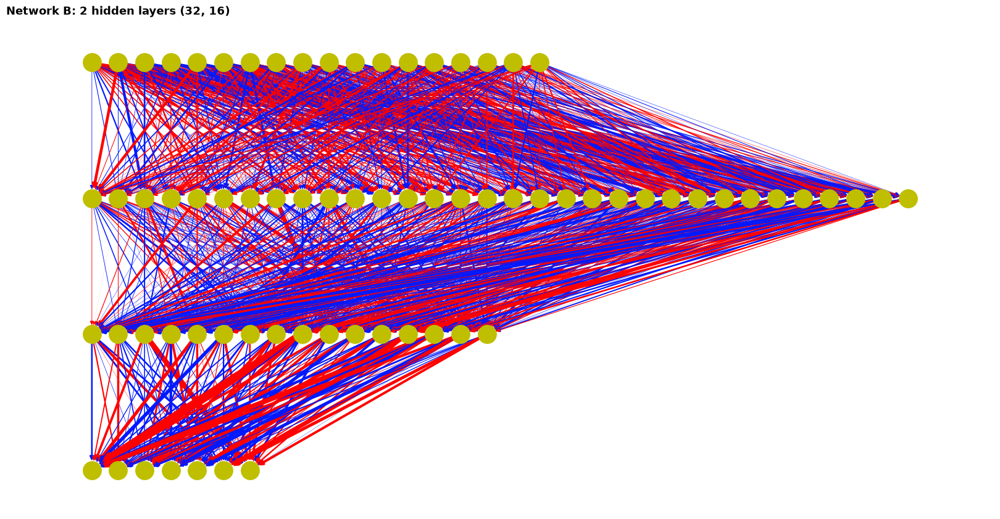

In [61]:
plt.figure(figsize=(16, 8))
show_ann(mlp_b)
plt.title('Network B: 2 hidden layers (32, 16)')
plt.show()

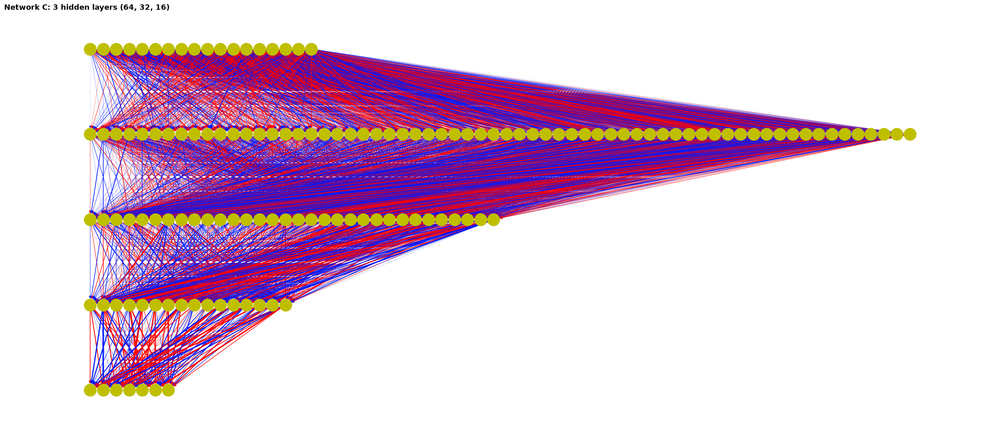

In [62]:
plt.figure(figsize=(24, 10))
show_ann(mlp_c)
plt.title('Network C: 3 hidden layers (64, 32, 16)')
plt.show()

## What inputs do the networks use?

In [41]:
first_layer = pd.DataFrame({
    'A': np.abs(mlp_a.coefs_[0]).mean(axis=1),
    'B': np.abs(mlp_b.coefs_[0]).mean(axis=1),
    'C': np.abs(mlp_c.coefs_[0]).mean(axis=1),
}, index=X.columns)

first_layer.sort_values('B', ascending=False).round(3)

,A,B,C
Age,0.700,0.706,0.369
Alcohol,0.629,0.601,0.301
Male,0.690,0.600,0.302
MainMeals,0.605,0.526,0.298
Snacking,0.523,0.511,0.285
Veggies,0.244,0.472,0.242
FamilyHistory,0.497,0.439,0.261
HighCalFood,0.573,0.424,0.268
Exercise,0.316,0.420,0.255
CountsCalories,0.606,0.420,0.231


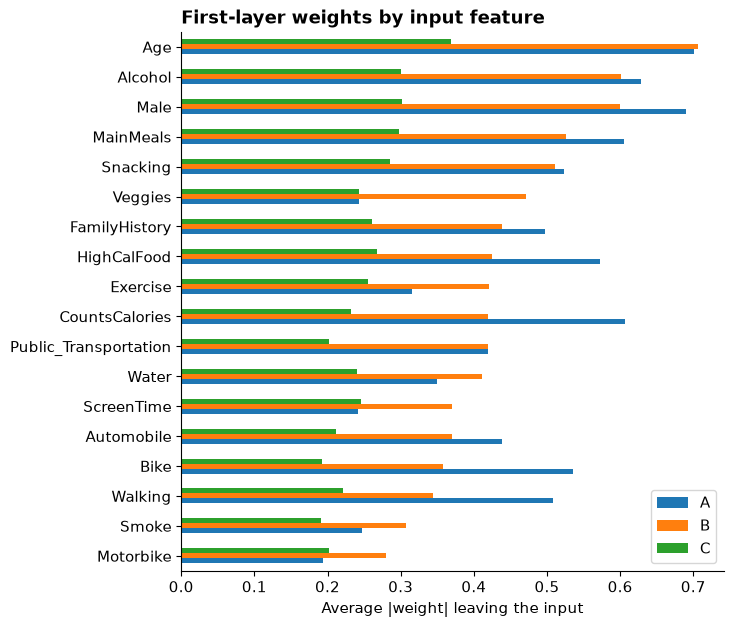

In [42]:
first_layer.sort_values('B').plot.barh(figsize=(7, 7))
plt.xlabel('Average |weight| leaving the input')
plt.title('First-layer weights by input feature')
plt.show()

## 